In [1]:
import pandas as pd
import matplotlib.pyplot as plt

print("Environment ready ✅")

Environment ready ✅


In [3]:
# Just check the column names
print("IDMC columns:", list(idmc.columns[:10]))
print("\nFirst few rows:")
idmc.head(3)

IDMC columns: ['Unnamed: 0.1', 'Unnamed: 0', 'ISO3', 'Name', 'Year', 'Start Date', 'event_name', 'Hazard Category', 'Hazard Type', 'Internal Displacements']

First few rows:


,Unnamed: 0.1,Unnamed: 0,ISO3,Name,Year,Start Date,event_name,Hazard Category,Hazard Type,Internal Displacements,countries_forUKonly,provinces,GID_1,districts,GID_2,country_only_info,num_provinces,num_districts
0,0,0,AB9,Abyei Area,2018,2018-07-01,Abyie: Flood - 01/07/2018,Weather related,Flood,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,1,AB9,Abyei Area,2019,2019-06-01,Abyei: Flood - southern parts - 01/06/2019,Weather related,Flood,40000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,2,AFG,Afghanistan,2008,2008-01-01,NaN,Weather related,Extreme temperature,NaN,NaN,NaN,NaN,NaN,NaN,AFG,NaN,NaN


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load all 3
disp = pd.read_csv("data/FLODIS_displacement.csv")
mort = pd.read_csv("data/FLODIS_mortality_damage.csv")
idmc = pd.read_csv("data/IDMC_2008_2021_provinces_districts.csv")

print("=== FLODIS Displacement ===")
print("Shape:", disp.shape)
print("Years:", disp["year"].min(), "→", disp["year"].max())

print("\n=== FLODIS Mortality/Damage ===")
print("Shape:", mort.shape)
print("Years:", mort["year"].min(), "→", mort["year"].max())

print("\n=== IDMC Full Dataset ===")
print("Shape:", idmc.shape)
print("\nHazard types:")
print(idmc["Hazard Type"].value_counts().head(10))

print("\nYear range:", idmc["Year"].min(), "→", idmc["Year"].max())

=== FLODIS Displacement ===
Shape: (335, 71)
Years: 2008.0 → 2018.0

=== FLODIS Mortality/Damage ===
Shape: (697, 74)
Years: 2000.0 → 2018.0

=== IDMC Full Dataset ===
Shape: (11731, 18)

Hazard types:
Hazard Type
Flood                  5482
Storm                  3217
Wildfire               1045
Wet mass movement      1041
Earthquake              455
Dry mass movement       154
Extreme temperature     139
Volcanic eruption        97
Drought                  44
Mass movement            38
Name: count, dtype: int64

Year range: 2008 → 2021


✅ Saved → flodis_temporal_distribution.png


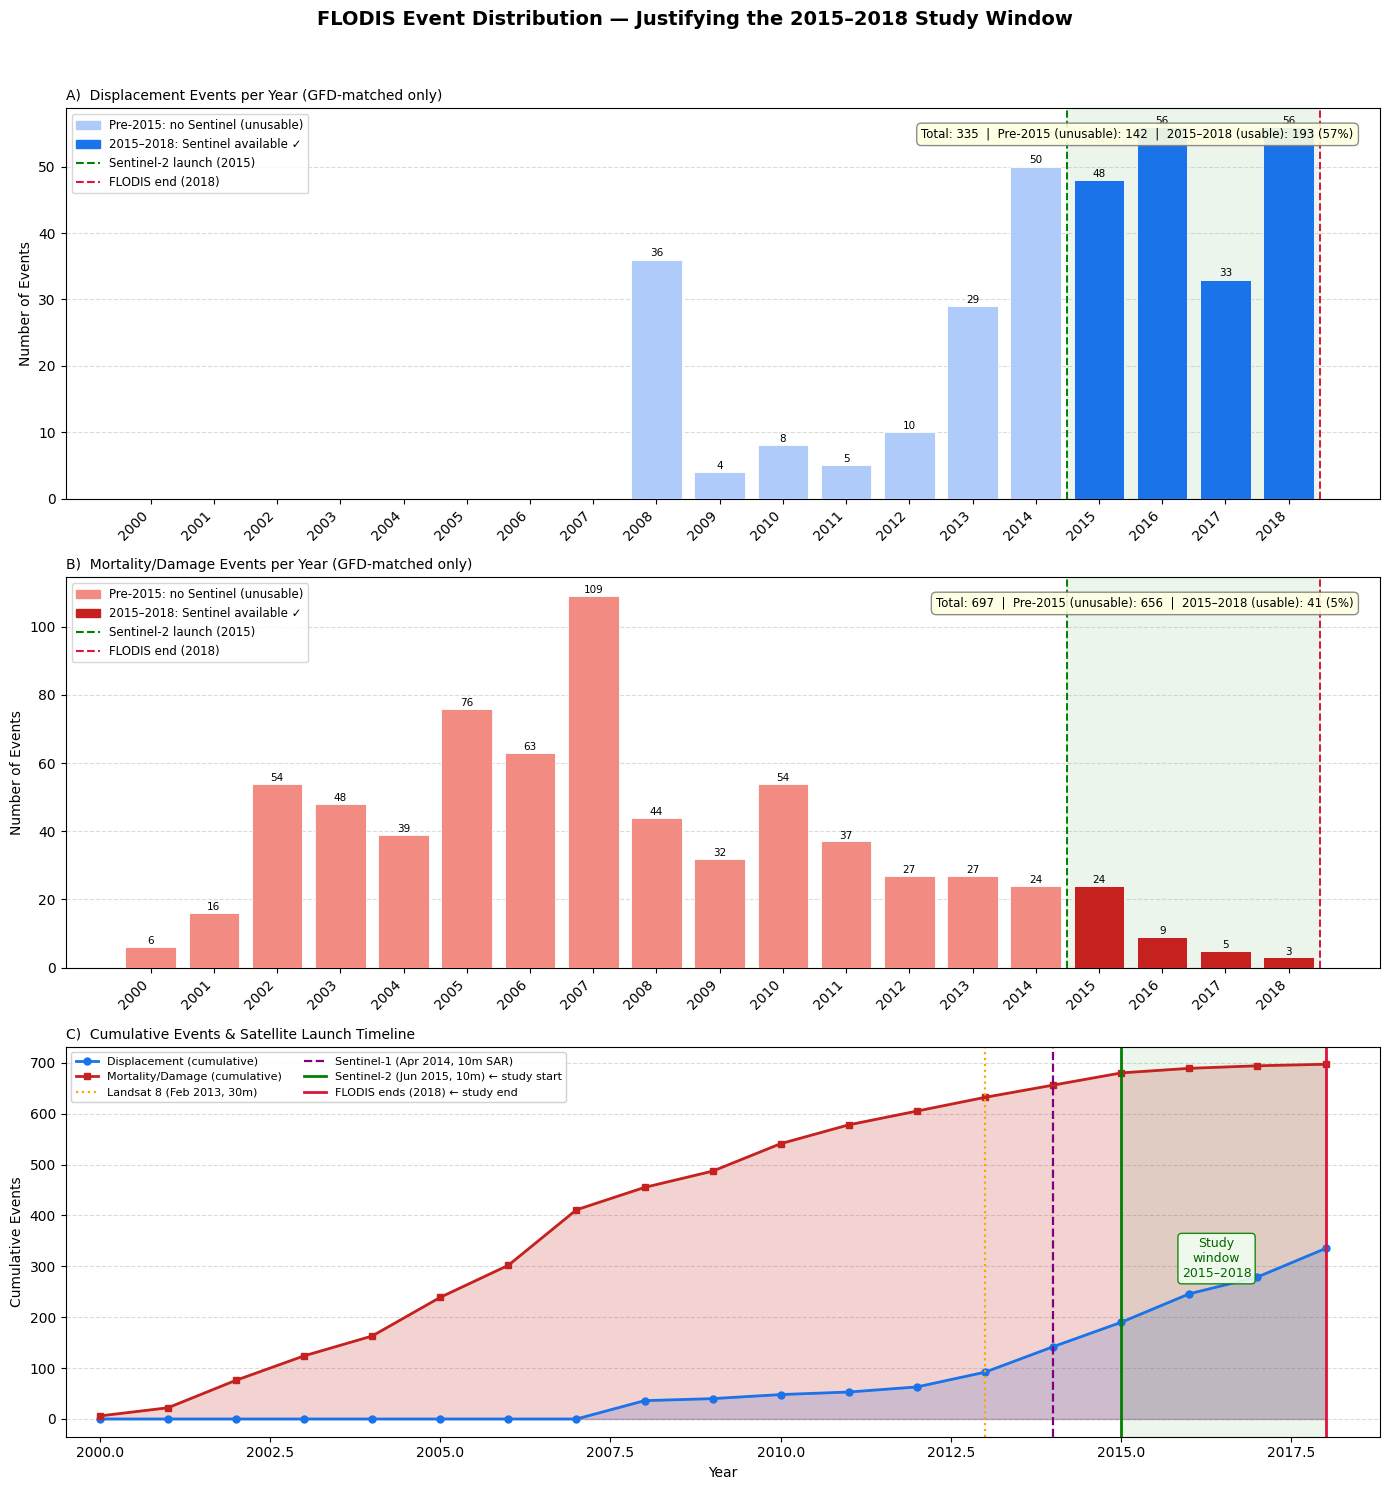

In [5]:
# ── Setup ────────────────────────────────────────────────────────────
SENTINEL_START = 2015
FLODIS_END     = 2018
all_years      = list(range(2000, 2019))
years          = np.array(all_years)
x              = np.arange(len(years))

COLOR_PRE    = "#AECBFA"
COLOR_USE    = "#1A73E8"
COLOR_MORT   = "#F28B82"
COLOR_MORT_U = "#C5221F"

# Filter matched events only
disp_matched = disp[disp["GFD_matches_nr"].notna()]
mort_matched = mort[mort["GFD_matches_nr"].notna()]

# Count per year
disp_per_year = disp_matched.groupby("year").size().reindex(all_years, fill_value=0)
mort_per_year = mort_matched.groupby("year").size().reindex(all_years, fill_value=0)

# Usable counts
n_disp_tot = int(disp_per_year.sum())
n_mort_tot = int(mort_per_year.sum())
n_disp_use = int(disp_per_year[years >= SENTINEL_START].sum())
n_mort_use = int(mort_per_year[years >= SENTINEL_START].sum())

# ── Figure ───────────────────────────────────────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(14, 15))
fig.suptitle("FLODIS Event Distribution — Justifying the 2015–2018 Study Window",
             fontsize=14, fontweight="bold", y=0.99)

def bar_colors(years, c_use, c_pre):
    return [c_use if SENTINEL_START <= y <= FLODIS_END else c_pre for y in years]

def shade(ax, x, years):
    idx_s = list(years).index(SENTINEL_START)
    idx_e = list(years).index(FLODIS_END)
    ax.axvspan(idx_s - 0.5, idx_e + 0.5, alpha=0.08, color="green", zorder=0)
    ax.axvline(idx_s - 0.5, color="green",   linestyle="--", linewidth=1.4)
    ax.axvline(idx_e + 0.5, color="crimson", linestyle="--", linewidth=1.4)

def annotate(ax, bars):
    for bar in bars:
        h = bar.get_height()
        if h > 0:
            ax.text(bar.get_x() + bar.get_width()/2, h + 0.2,
                    str(int(h)), ha="center", va="bottom", fontsize=7.5)

import matplotlib.patches as mpatches

def add_legend(ax, c_pre, c_use):
    p1 = mpatches.Patch(color=c_pre, label=f"Pre-{SENTINEL_START}: no Sentinel (unusable)")
    p2 = mpatches.Patch(color=c_use, label=f"{SENTINEL_START}–{FLODIS_END}: Sentinel available ✓")
    l1 = plt.Line2D([0],[0], color="green",   linestyle="--", label="Sentinel-2 launch (2015)")
    l2 = plt.Line2D([0],[0], color="crimson", linestyle="--", label="FLODIS end (2018)")
    ax.legend(handles=[p1, p2, l1, l2], fontsize=8.5, loc="upper left")

# ── Plot A: Displacement ─────────────────────────────────────────────
ax1 = axes[0]
bars1 = ax1.bar(x, disp_per_year.values,
                color=bar_colors(years, COLOR_USE, COLOR_PRE),
                edgecolor="white", linewidth=0.6, zorder=3)
annotate(ax1, bars1)
shade(ax1, x, years)
add_legend(ax1, COLOR_PRE, COLOR_USE)
ax1.set_title("A)  Displacement Events per Year (GFD-matched only)",
              fontsize=10, loc="left")
ax1.set_ylabel("Number of Events")
ax1.set_xticks(x)
ax1.set_xticklabels(years, rotation=45, ha="right")
ax1.yaxis.grid(True, linestyle="--", alpha=0.45)
ax1.set_axisbelow(True)
ax1.text(0.98, 0.95,
         f"Total: {n_disp_tot}  |  Pre-2015 (unusable): {n_disp_tot-n_disp_use}"
         f"  |  2015–2018 (usable): {n_disp_use} ({100*n_disp_use//n_disp_tot}%)",
         transform=ax1.transAxes, fontsize=8.5, va="top", ha="right",
         bbox=dict(boxstyle="round,pad=0.4", facecolor="lightyellow",
                   edgecolor="gray", alpha=0.9))

# ── Plot B: Mortality/Damage ──────────────────────────────────────────
ax2 = axes[1]
bars2 = ax2.bar(x, mort_per_year.values,
                color=bar_colors(years, COLOR_MORT_U, COLOR_MORT),
                edgecolor="white", linewidth=0.6, zorder=3)
annotate(ax2, bars2)
shade(ax2, x, years)
add_legend(ax2, COLOR_MORT, COLOR_MORT_U)
ax2.set_title("B)  Mortality/Damage Events per Year (GFD-matched only)",
              fontsize=10, loc="left")
ax2.set_ylabel("Number of Events")
ax2.set_xticks(x)
ax2.set_xticklabels(years, rotation=45, ha="right")
ax2.yaxis.grid(True, linestyle="--", alpha=0.45)
ax2.set_axisbelow(True)
ax2.text(0.98, 0.95,
         f"Total: {n_mort_tot}  |  Pre-2015 (unusable): {n_mort_tot-n_mort_use}"
         f"  |  2015–2018 (usable): {n_mort_use} ({100*n_mort_use//n_mort_tot}%)",
         transform=ax2.transAxes, fontsize=8.5, va="top", ha="right",
         bbox=dict(boxstyle="round,pad=0.4", facecolor="lightyellow",
                   edgecolor="gray", alpha=0.9))

# ── Plot C: Cumulative + timeline ─────────────────────────────────────
ax3 = axes[2]
disp_cum = disp_per_year.cumsum().values
mort_cum = mort_per_year.cumsum().values

ax3.fill_between(years, 0, disp_cum, alpha=0.2, color=COLOR_USE)
ax3.fill_between(years, 0, mort_cum, alpha=0.2, color=COLOR_MORT_U)
ax3.plot(years, disp_cum, color=COLOR_USE,    lw=2, marker="o", ms=5,
         label="Displacement (cumulative)")
ax3.plot(years, mort_cum, color=COLOR_MORT_U, lw=2, marker="s", ms=5,
         label="Mortality/Damage (cumulative)")

ax3.axvline(2013, color="orange", linestyle=":",  lw=1.6, label="Landsat 8 (Feb 2013, 30m)")
ax3.axvline(2014, color="purple", linestyle="--", lw=1.6, label="Sentinel-1 (Apr 2014, 10m SAR)")
ax3.axvline(2015, color="green",  linestyle="-",  lw=2.0, label="Sentinel-2 (Jun 2015, 10m) ← study start")
ax3.axvline(2018, color="crimson",linestyle="-",  lw=2.0, label="FLODIS ends (2018) ← study end")
ax3.axvspan(2015, 2018, alpha=0.07, color="green")
ax3.text(2016.4, max(mort_cum)*0.4, "Study\nwindow\n2015–2018",
         fontsize=9, ha="center", color="darkgreen",
         bbox=dict(boxstyle="round", facecolor="honeydew",
                   edgecolor="green", alpha=0.9))

ax3.set_title("C)  Cumulative Events & Satellite Launch Timeline",
              fontsize=10, loc="left")
ax3.set_ylabel("Cumulative Events")
ax3.set_xlabel("Year")
ax3.set_xlim(1999.5, 2018.8)
ax3.yaxis.grid(True, linestyle="--", alpha=0.45)
ax3.set_axisbelow(True)
ax3.legend(fontsize=8, loc="upper left", ncol=2, framealpha=0.9)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig("flodis_temporal_distribution.png", dpi=150, bbox_inches="tight")
print("✅ Saved → flodis_temporal_distribution.png")
plt.show()

In [6]:
# ── Filter: 2015-2018 usable events only ─────────────────────────
disp_usable = disp_matched[
    (disp_matched["year"] >= 2015) & 
    (disp_matched["year"] <= 2018)
].copy()

mort_usable = mort_matched[
    (mort_matched["year"] >= 2015) & 
    (mort_matched["year"] <= 2018)
].copy()

# ── Print summary ─────────────────────────────────────────────────
print("=== YOUR FINAL DATASET ===")
print(f"\nDisplacement events (2015-2018): {len(disp_usable)}")
print(f"  → Target: displacements")
print(f"  → Missing targets: {disp_usable['displacements'].isna().sum()}")

print(f"\nMortality/Damage events (2015-2018): {len(mort_usable)}")
print(f"  → Target deaths:  {mort_usable['total_deaths'].isna().sum()} missing")
print(f"  → Target damages: {mort_usable['total_damages_(000_USD)'].isna().sum()} missing")

# ── Extract GFD IDs (needed for GEE) ─────────────────────────────
print("\n=== GFD IDs FOR GEE ===")
print(f"Displacement GFD IDs: {disp_usable['GFD_matches_nr'].tolist()[:5]} ...")
print(f"Mortality GFD IDs:    {mort_usable['GFD_matches_nr'].tolist()[:5]} ...")

# ── Save ──────────────────────────────────────────────────────────
disp_usable.to_csv("data/disp_2015_2018.csv", index=False)
mort_usable.to_csv("data/mort_2015_2018.csv", index=False)
print("\n✅ Saved:")
print("   data/disp_2015_2018.csv")
print("   data/mort_2015_2018.csv")

=== YOUR FINAL DATASET ===

Displacement events (2015-2018): 193
  → Target: displacements
  → Missing targets: 0

Mortality/Damage events (2015-2018): 41
  → Target deaths:  10 missing
  → Target damages: 24 missing

=== GFD IDs FOR GEE ===
Displacement GFD IDs: ['4272', '4272', '4645', '4645', '4233'] ...
Mortality GFD IDs:    ['4219', '4280', '4326', '4462', '4233'] ...

✅ Saved:
   data/disp_2015_2018.csv
   data/mort_2015_2018.csv


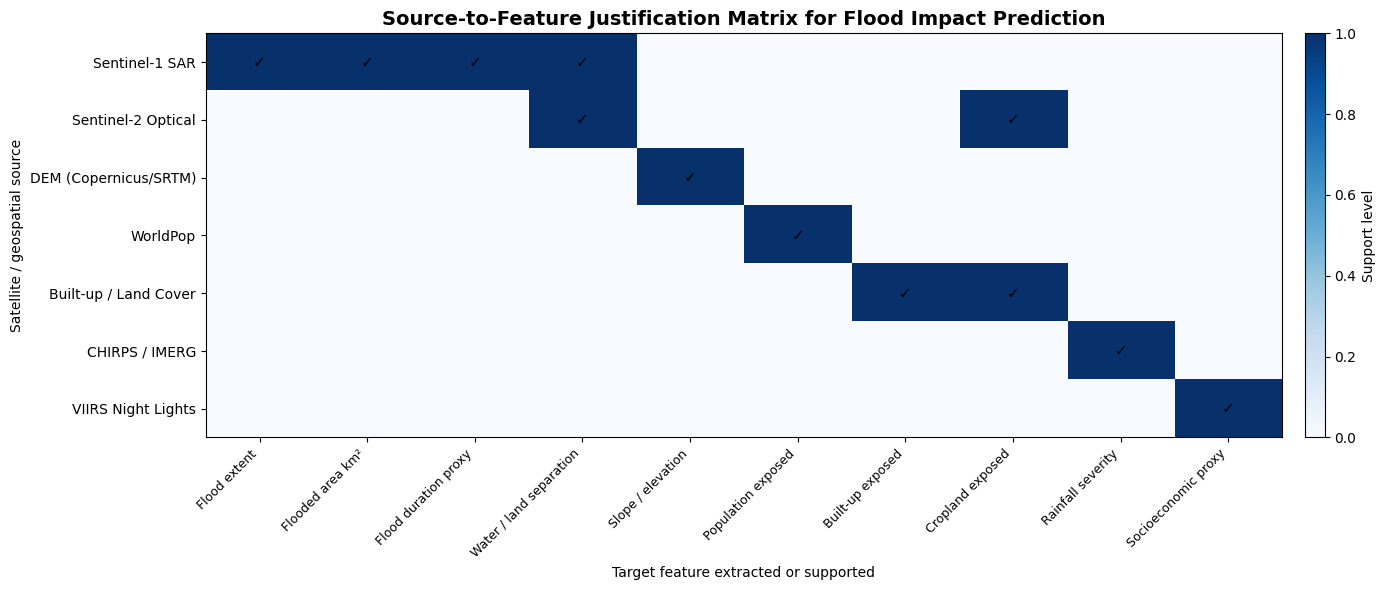

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("default")

# ============================================================
# 1) SOURCE -> FEATURE MATRIX
# ============================================================

sources = [
    "Sentinel-1 SAR",
    "Sentinel-2 Optical",
    "DEM (Copernicus/SRTM)",
    "WorldPop",
    "Built-up / Land Cover",
    "CHIRPS / IMERG",
    "VIIRS Night Lights"
]

features = [
    "Flood extent",
    "Flooded area km²",
    "Flood duration proxy",
    "Water / land separation",
    "Slope / elevation",
    "Population exposed",
    "Built-up exposed",
    "Cropland exposed",
    "Rainfall severity",
    "Socioeconomic proxy"
]

# 1 = strongly supports feature, 0 = no
matrix = np.array([
    [1, 1, 1, 1, 0, 0, 0, 0, 0, 0],  # Sentinel-1
    [0, 0, 0, 1, 0, 0, 0, 1, 0, 0],  # Sentinel-2
    [0, 0, 0, 0, 1, 0, 0, 0, 0, 0],  # DEM
    [0, 0, 0, 0, 0, 1, 0, 0, 0, 0],  # WorldPop
    [0, 0, 0, 0, 0, 0, 1, 1, 0, 0],  # Built-up / land cover
    [0, 0, 0, 0, 0, 0, 0, 0, 1, 0],  # Rainfall
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 1],  # Night lights
])

fig, ax = plt.subplots(figsize=(14, 6))
im = ax.imshow(matrix, aspect="auto", cmap="Blues")

ax.set_xticks(np.arange(len(features)))
ax.set_xticklabels(features, rotation=45, ha="right", fontsize=9)
ax.set_yticks(np.arange(len(sources)))
ax.set_yticklabels(sources, fontsize=10)

for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        ax.text(j, i, "✓" if matrix[i, j] == 1 else "",
                ha="center", va="center", fontsize=11, color="black")

ax.set_title("Source-to-Feature Justification Matrix for Flood Impact Prediction",
             fontsize=14, fontweight="bold")
ax.set_xlabel("Target feature extracted or supported")
ax.set_ylabel("Satellite / geospatial source")

cbar = plt.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cbar.set_label("Support level")

plt.tight_layout()
plt.show()

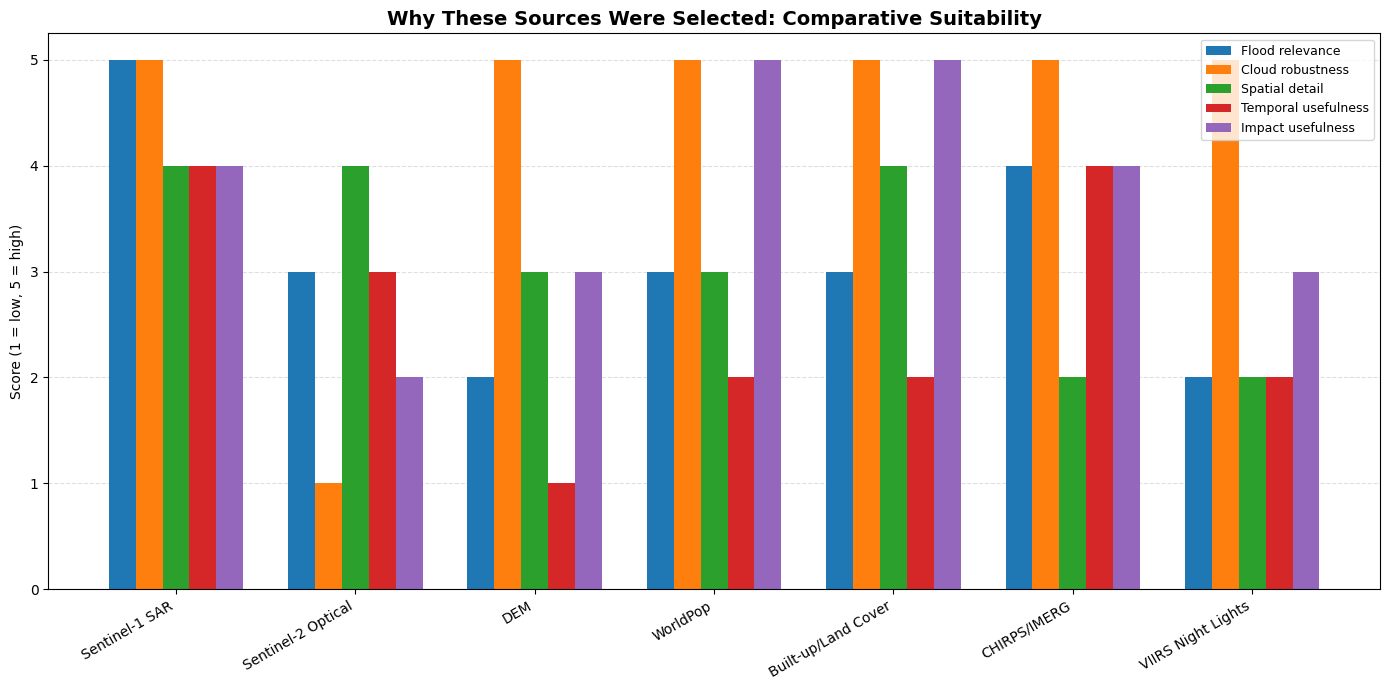

In [8]:
# ============================================================
# 2) SOURCE SUITABILITY SCORES
# ============================================================

score_df = pd.DataFrame({
    "Source": [
        "Sentinel-1 SAR",
        "Sentinel-2 Optical",
        "DEM",
        "WorldPop",
        "Built-up/Land Cover",
        "CHIRPS/IMERG",
        "VIIRS Night Lights"
    ],
    "Flood relevance": [5, 3, 2, 3, 3, 4, 2],
    "Cloud robustness": [5, 1, 5, 5, 5, 5, 5],
    "Spatial detail": [4, 4, 3, 3, 4, 2, 2],
    "Temporal usefulness": [4, 3, 1, 2, 2, 4, 2],
    "Impact usefulness": [4, 2, 3, 5, 5, 4, 3]
})

score_df = score_df.set_index("Source")

fig, ax = plt.subplots(figsize=(14, 7))

x = np.arange(len(score_df.index))
width = 0.15

for k, col in enumerate(score_df.columns):
    ax.bar(x + k * width, score_df[col].values, width=width, label=col)

ax.set_xticks(x + width * 2)
ax.set_xticklabels(score_df.index, rotation=30, ha="right")
ax.set_ylabel("Score (1 = low, 5 = high)")
ax.set_title("Why These Sources Were Selected: Comparative Suitability",
             fontsize=14, fontweight="bold")
ax.legend(fontsize=9)
ax.yaxis.grid(True, linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

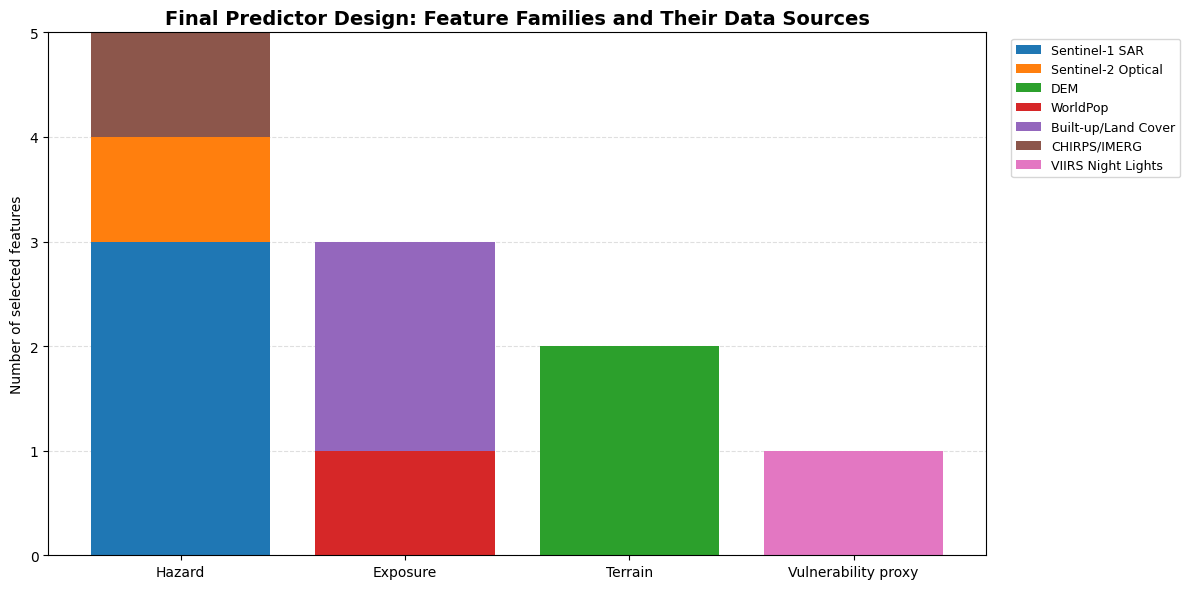

In [9]:
# ============================================================
# 3) FINAL FEATURE GROUPS BY SOURCE FAMILY
# ============================================================

feature_groups = pd.DataFrame({
    "Group": ["Hazard", "Exposure", "Terrain", "Vulnerability proxy"],
    "Sentinel-1 SAR": [3, 0, 0, 0],
    "Sentinel-2 Optical": [1, 0, 0, 0],
    "DEM": [0, 0, 2, 0],
    "WorldPop": [0, 1, 0, 0],
    "Built-up/Land Cover": [0, 2, 0, 0],
    "CHIRPS/IMERG": [1, 0, 0, 0],
    "VIIRS Night Lights": [0, 0, 0, 1]
})

feature_groups = feature_groups.set_index("Group")

fig, ax = plt.subplots(figsize=(12, 6))
bottom = np.zeros(len(feature_groups))

for col in feature_groups.columns:
    vals = feature_groups[col].values
    ax.bar(feature_groups.index, vals, bottom=bottom, label=col)
    bottom += vals

ax.set_ylabel("Number of selected features")
ax.set_title("Final Predictor Design: Feature Families and Their Data Sources",
             fontsize=14, fontweight="bold")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
ax.yaxis.grid(True, linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [10]:
summary_table = pd.DataFrame({
    "Source": [
        "Sentinel-1 SAR",
        "Sentinel-2 Optical",
        "DEM",
        "WorldPop",
        "Built-up / Land Cover",
        "CHIRPS / IMERG",
        "VIIRS Night Lights"
    ],
    "Why chosen": [
        "Core source for flood extent; all-weather; suitable during flood events",
        "Useful complementary optical information when cloud-free",
        "Captures terrain controls such as slope and elevation",
        "Needed to quantify exposed population",
        "Needed to estimate exposed built-up and cropland",
        "Provides rainfall severity / triggering context",
        "Proxy for economic activity / development level"
    ],
    "Main features": [
        "Flood extent, flooded area, flood fraction, duration proxy",
        "Water separation, land cover context, cropland context",
        "Elevation, slope",
        "Population exposed",
        "Built-up exposed, cropland exposed",
        "Rainfall intensity / anomaly",
        "Night-light exposure / wealth proxy"
    ]
})

print(summary_table.to_string(index=False))

               Source                                                              Why chosen                                              Main features
       Sentinel-1 SAR Core source for flood extent; all-weather; suitable during flood events Flood extent, flooded area, flood fraction, duration proxy
   Sentinel-2 Optical                Useful complementary optical information when cloud-free     Water separation, land cover context, cropland context
                  DEM                   Captures terrain controls such as slope and elevation                                           Elevation, slope
             WorldPop                                   Needed to quantify exposed population                                         Population exposed
Built-up / Land Cover                        Needed to estimate exposed built-up and cropland                         Built-up exposed, cropland exposed
       CHIRPS / IMERG                         Provides rainfall severity / trigger

In [15]:
import pandas as pd

df = pd.read_csv("data/satellite_yearly_counts_roi.csv")
print(df.columns)
df.head()

Index(['year', 'Sentinel-1', 'Sentinel-2 cloud<20%', 'Landsat-8 cloud<20%'], dtype='str')


,year,Sentinel-1,Sentinel-2 cloud<20%,Landsat-8 cloud<20%
0,"2,012",0,0,0
1,"2,013",0,0,61
2,"2,014",45,0,75
3,"2,015",158,47,64
4,"2,016",218,224,82


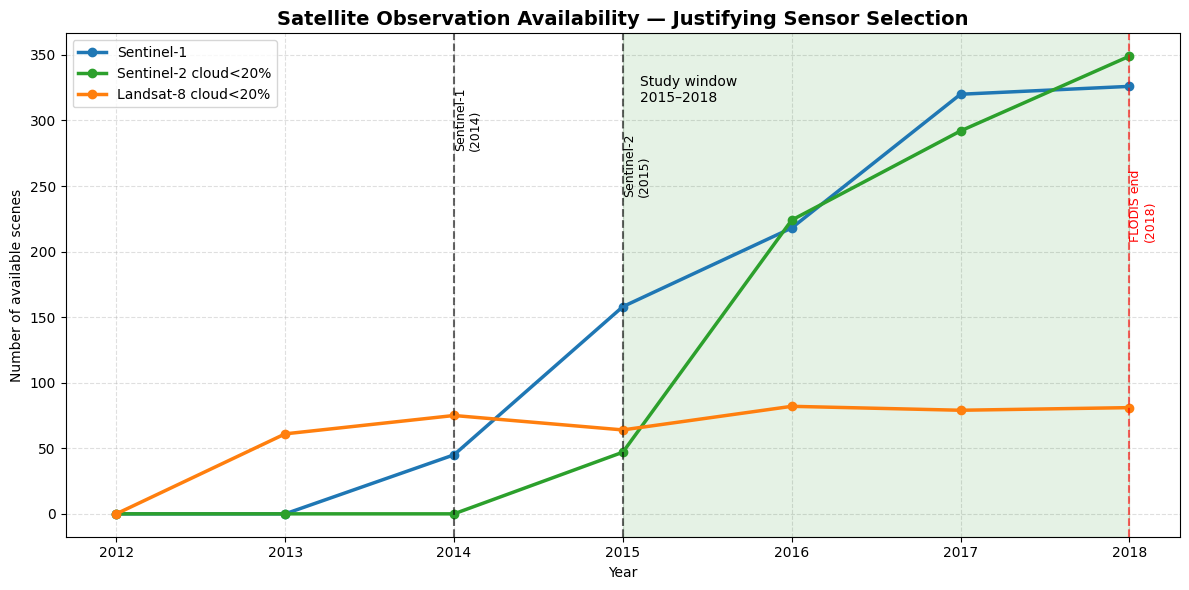

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

# Load data
df = pd.read_csv("data/satellite_yearly_counts_roi.csv")

# Fix year (remove comma issue like "2,012")
df['year'] = df['year'].astype(str).str.replace(',', '').astype(int)

# Convert wide → long format
df_long = df.melt(id_vars='year', var_name='sensor', value_name='count')

# Convert count to numeric
df_long['count'] = pd.to_numeric(df_long['count'], errors='coerce')

# ============================
# Plot
# ============================
plt.style.use("default")
fig, ax = plt.subplots(figsize=(12, 6))

colors = ['#1f77b4', '#2ca02c', '#ff7f0e']

for sensor, color in zip(df_long['sensor'].unique(), colors):
    sub = df_long[df_long['sensor'] == sensor].sort_values('year')
    ax.plot(
        sub['year'], sub['count'],
        marker='o', linewidth=2.5,
        label=sensor, color=color
    )

# Study window
ax.axvspan(2015, 2018, color='green', alpha=0.1)
ax.text(2015.1, df_long['count'].max() * 0.9,
        "Study window\n2015–2018", fontsize=10)

# Timeline lines
ax.axvline(2014, linestyle='--', color='black', alpha=0.6)
ax.text(2014, df_long['count'].max() * 0.8,
        "Sentinel-1\n(2014)", rotation=90, fontsize=9)

ax.axvline(2015, linestyle='--', color='black', alpha=0.6)
ax.text(2015, df_long['count'].max() * 0.7,
        "Sentinel-2\n(2015)", rotation=90, fontsize=9)

ax.axvline(2018, linestyle='--', color='red', alpha=0.6)
ax.text(2018, df_long['count'].max() * 0.6,
        "FLODIS end\n(2018)", rotation=90, fontsize=9, color='red')

# Labels
ax.set_title("Satellite Observation Availability — Justifying Sensor Selection",
             fontsize=14, fontweight='bold')
ax.set_xlabel("Year")
ax.set_ylabel("Number of available scenes")

ax.legend()
ax.grid(True, linestyle='--', alpha=0.4)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

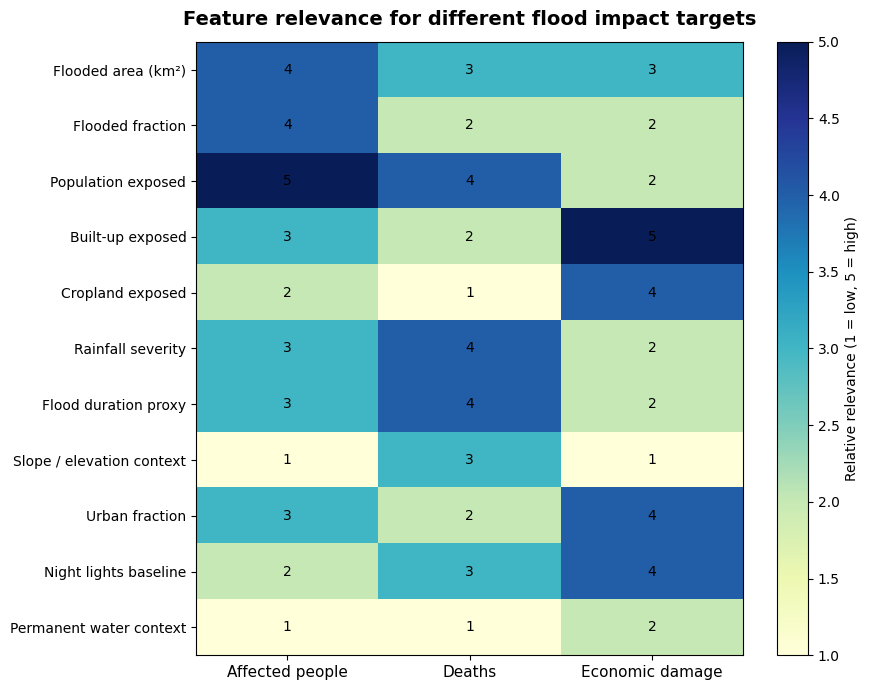

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

feature_target = pd.DataFrame({
    "Feature": [
        "Flooded area (km²)",
        "Flooded fraction",
        "Population exposed",
        "Built-up exposed",
        "Cropland exposed",
        "Rainfall severity",
        "Flood duration proxy",
        "Slope / elevation context",
        "Urban fraction",
        "Night lights baseline",
        "Permanent water context"
    ],
    "Affected people": [4, 4, 5, 3, 2, 3, 3, 1, 3, 2, 1],
    "Deaths":          [3, 2, 4, 2, 1, 4, 4, 3, 2, 3, 1],
    "Economic damage": [3, 2, 2, 5, 4, 2, 2, 1, 4, 4, 2]
})

feature_target = feature_target.set_index("Feature")

fig, ax = plt.subplots(figsize=(9, 7))

im = ax.imshow(feature_target.values, cmap="YlGnBu", aspect="auto", vmin=1, vmax=5)

ax.set_xticks(np.arange(len(feature_target.columns)))
ax.set_xticklabels(feature_target.columns, fontsize=11)

ax.set_yticks(np.arange(len(feature_target.index)))
ax.set_yticklabels(feature_target.index, fontsize=10)

for i in range(feature_target.shape[0]):
    for j in range(feature_target.shape[1]):
        ax.text(
            j, i, feature_target.iloc[i, j],
            ha="center", va="center",
            color="black", fontsize=10
        )

ax.set_title(
    "Feature relevance for different flood impact targets",
    fontsize=14, fontweight="bold", pad=12
)

cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Relative relevance (1 = low, 5 = high)", fontsize=10)

plt.tight_layout()
plt.show()